<a href="https://colab.research.google.com/github/moushi21/microduck_rl/blob/develop/Microduck_VelStand%E3%83%86%E3%82%B9%E3%83%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

１．uvのインストールとリポジトリの取得を開始します。

Colabのランタイムタイプは、L4を選択してください。

In [1]:
# 1. uv のインストールとリポジトリの取得
!pip install uv
!git clone https://github.com/moushi21/microduck_rl
%cd microduck_rl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 132.8 MB/s eta 0:00:00
Cloning into 'microduck_rl'...
remote: Enumerating objects: 9573, done.
remote: Counting objects: 100% (2245/2245), done.
remote: Compressing objects: 100% (285/285), done.
remote: Total 9573 (delta 2060), reused 1960 (delta 1960), pack-reused 7328 (from 3)
Receiving objects: 100% (9573/9573), 31.92 MiB | 7.02 MiB/s, done.
Resolving deltas: 100% (6552/6552), done.
/content/microduck_rl


２．依存関係のセットアップ（PyTorch CUDA対応）

In [2]:
# 2. 依存関係のセットアップ (PyTorch CUDA対応)
!uv pip install --system torch torchvision --index-url https://download.pytorch.org/whl/cu121
!uv pip install --system -e .

Using Python 3.13.15 environment at: /usr
Checked 2 packages in 113ms
Using Python 3.13.15 environment at: /usr
Resolved 133 packages in 1.64s
Prepared 54 packages in 31.57s
Uninstalled 17 packages in 637ms
Installed 54 packages in 224ms
 + bcrypt==5.0.0
 + better-actuator-models==1.0.1 (from git+https://github.com/Rhoban/bam.git@57d13ead53206a6bf0db3d66f86506ae8c2ce01a)
 + colorama==0.4.6
 - decorator==4.4.2
 + decorator==5.3.1
 + deprecated==3.0.0
 + fabric==3.2.3
 + gitdb==4.0.12
 + gitpython==3.2.1
 + glfw==2.11.0
 + invoke==2.2.1
 + jedi==0.20.1
 - matplotlib==3.10.0
 + matplotlib==3.11.2
 + mediapy==1.2.7
 + mjlab==1.3.0
 + mjlab-microduck==0.1.0 (from file:///content/microduck_rl)
 + mjviser==0.0.14
 + msgspec==0.22.0
 + mujoco==3.16.0
 + mujoco-warp==3.8.1
 - nvidia-cublas-cu12==12.9.2.10
 + nvidia-cublas-cu12==12.8.4.1
 - nvidia-cuda-cupti-cu12==12.9.79
 + nvidia-cuda-cupti-cu12==12.8.90
 - nvidia-cuda-nvrtc-cu12==12.9.86
 + nvidia-cuda-nvrtc-cu12==12.8.93
 - nvidia-cuda-runti

３．ColabのシークレットからWANDB_API_KEYを取得し、wandbログイン

In [3]:
# 3. Colab のシークレットから WANDB_API_KEY を取得し、学習を実行
import os, wandb
from google.colab import userdata

try:
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
except userdata.SecretNotFoundError:
    print("エラー: Colabのシークレット(左メニューの🔑アイコン)に 'WANDB_API_KEY' が登録されていません。")

wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: moushi21 (moushi21-dynasoft-corp-) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

４．MicroDuckのボールキックタスクを学習します。

（１）学習のデフォルトは、50,000iteration、並列学習はパラメータとして、4096体としています。

（２）ログが大量に出力されるので、/dev/nullに捨てています。進捗状況は、wandbにて確認を行います。

（３）wandbによる進捗状況の確認手段としては、強化学習の学習ストラテジーである、カリキュラム学習のログが目安となります。2,000iteration(step)を超えると、他のカリキュラム項目もクリアしていますので、学習を停止しても問題ありません。

（４）シミュレータMjlabにて、安定した動作を得るためには、学習時間の目安としては、３〜４時間程度は必要となります。
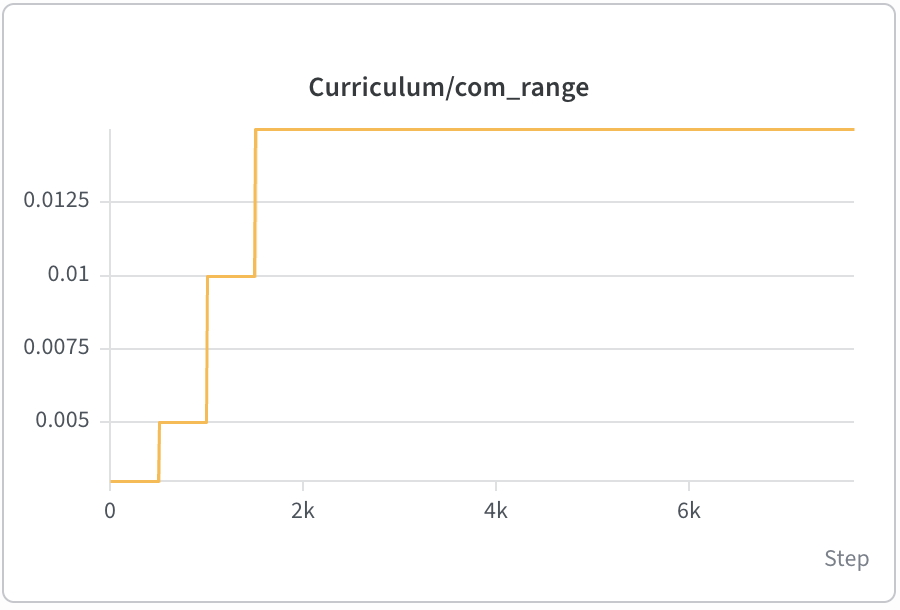

In [ ]:
!uv run train Mjlab-VelStand-Flat-MicroDuck --env.scene.num-envs 4096 > /dev/null 2>&1

５．wandbの該当ランID（例：pg0bh5k9）を指定し、動画ファイルを生成します。内部詳細の実行手順は以下の通り

（１）wandbチェックポイントの取得

（２）61次元のObservationを元に、シミュレーションでの推論

（３）動画レンダリング

※注意：1分以上の録画を行う場合は、約３時間は必要となります。（３時間経過した後に停止してください。）

In [12]:
import os

# GPU描画環境変数の設定
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# ViserのGUIエラーを回避するため、--viewer native と xvfb-run を用いてヘッドレスで実行し、動画を作成します
# !xvfb-run --auto-servernum --server-args="-screen 0 1024x768x24" uv run play Mjlab-BallKick-Flat-MicroDuck --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/runs/pg0bh5k9 --num-envs 1 --video True --video-length 2400 --viewer native
!xvfb-run --auto-servernum --server-args="-screen 0 1024x768x24" uv run play Mjlab-VelStand-Flat-MicroDuck --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/nip9ar13 --num-envs 5 --video True --video-length 3500 --viewer native

[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[mdp] Patch 5 active: MICRODUCK_WARM_START=1 restarts curricula after checkpoint load
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
[INFO]: Loading checkpoint: model_2000.pt (run: nip9ar13, downloaded)
/content/microduck_rl/.venv/lib/python3.12/site-packages/mjlab/entity/entity.py:149: UserWarning: Actuator config matched 14 joint(s) but the same expressions also match 7 site(s): imu, left_foot, head_camera, tof, head_imu, mouth_tip, right_foot. Add a separate config with transmission_type=TransmissionType.SITE if those should be actuated too.
  self._add_actuators()
Warp 1.12.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA L4" (22 GiB, sm_89, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.0
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon

６．ビデオを再生します。

※注意：タスク毎に、mp4ファイルが出力される場所が、異なる場合があります。logs/rsl_rlディレクトリ内を検索し、video_pathを設定の上、再生してください。

In [13]:
import os
from IPython.display import HTML
from base64 import b64encode

# 動画ファイルの正確な保存先
video_path = "logs/rsl_rl/velstand/wandb_checkpoints/nip9ar13/videos/play/rl-video-step-0.mp4"

if os.path.exists(video_path):
    print(f"動画を読み込み中: {video_path}")
    mp4_data = b64encode(open(video_path, 'rb').read()).decode()
    # display(HTML(f'<video width="640" height="480" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
    display(HTML(f'<video width="1024" height="768" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
else:
    print(f"動画ファイルが見つかりません。作成用セルが正常に終了したか確認してください。パス: {video_path}")

動画を読み込み中: logs/rsl_rl/velstand/wandb_checkpoints/nip9ar13/videos/play/rl-video-step-0.mp4
